<a href="https://colab.research.google.com/github/Lekhana-Y/ML/blob/main/Regression_Mi_l8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

# Read the uploaded CSV file automatically
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Uploaded file:", file_name)
print("Dataset shape:", df.shape)
display(df.head())


Saving DailyDelhiClimateTest.csv to DailyDelhiClimateTest.csv
Uploaded file: DailyDelhiClimateTest.csv
Dataset shape: (114, 5)


,date,meantemp,humidity,wind_speed,meanpressure
0,2017-01-01,15.913043,85.869565,2.743478,59.000000
1,2017-01-02,18.500000,77.222222,2.894444,1018.277778
2,2017-01-03,17.111111,81.888889,4.016667,1018.333333
3,2017-01-04,18.700000,70.050000,4.545000,1015.700000
4,2017-01-05,18.388889,74.944444,3.300000,1014.333333


Linear

MAE: 2.3417665300330093
MSE: 7.318334093086142
RMSE: 2.7052419657188045
R2: 0.8200968830995107


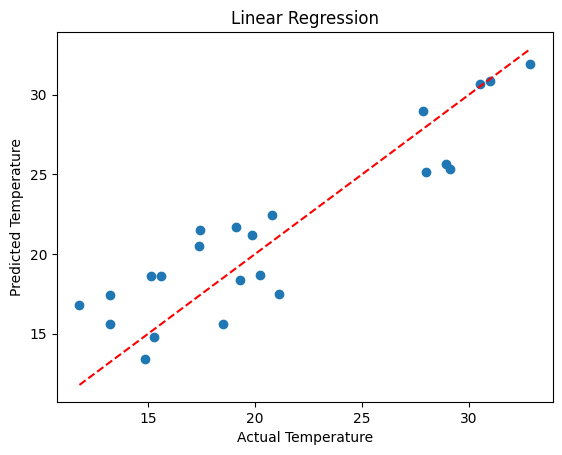

In [42]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df[['humidity', 'wind_speed', 'meanpressure']]
y = df['meantemp']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred))
print("MSE:", mean_squared_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2:", r2_score(y_test, pred))

plt.scatter(y_test, pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Temperature")
plt.ylabel("Predicted Temperature")
plt.title("Linear Regression")
plt.show()


polynomial

MAE: 2.194502937849028
MSE: 6.9366791068216545
RMSE: 2.6337576021383695
R2: 0.8294789256157796


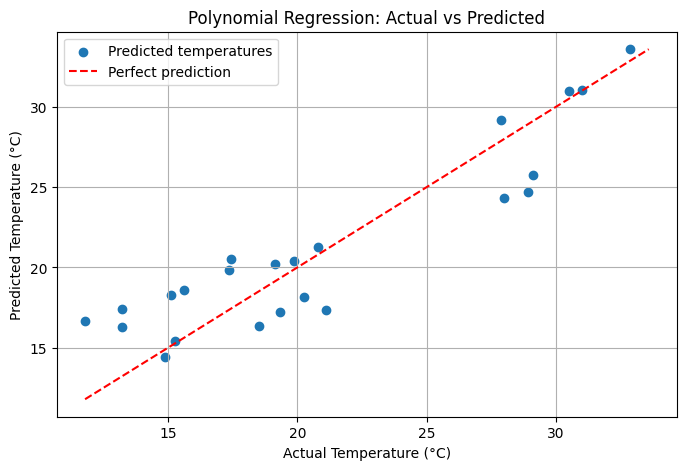

In [47]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Recreate regression variables
X_reg = df[['humidity', 'wind_speed', 'meanpressure']]
y_reg = df['meantemp']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

poly = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
poly.fit(X_train_reg, y_train_reg)
pred_poly = poly.predict(X_test_reg)

print("MAE:", mean_absolute_error(y_test_reg, pred_poly))
print("MSE:", mean_squared_error(y_test_reg, pred_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_test_reg, pred_poly)))
print("R2:", r2_score(y_test_reg, pred_poly))

# Plot actual vs predicted temperature
plt.figure(figsize=(8, 5))
plt.scatter(y_test_reg, pred_poly, label="Predicted temperatures")

low = min(y_test_reg.min(), pred_poly.min())
high = max(y_test_reg.max(), pred_poly.max())
plt.plot([low, high], [low, high], 'r--', label="Perfect prediction")

plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.title("Polynomial Regression: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()


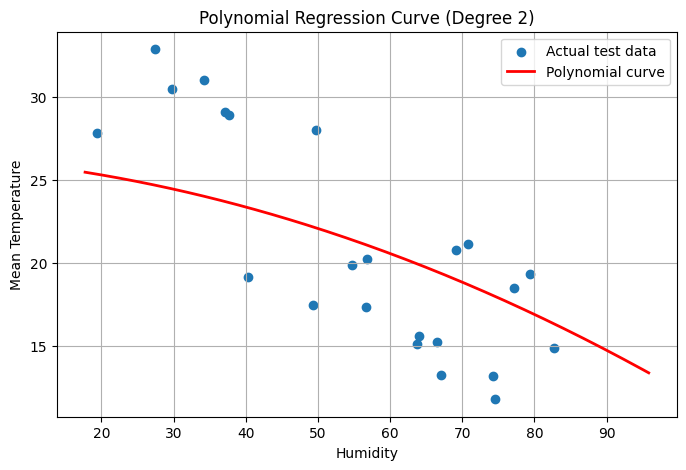

In [48]:

# Create smooth humidity values
humidity_range = np.linspace(
    X_train_reg['humidity'].min(),
    X_train_reg['humidity'].max(),
    200
)

# Keep other features constant
curve_data = pd.DataFrame({
    'humidity': humidity_range,
    'wind_speed': X_train_reg['wind_speed'].mean(),
    'meanpressure': X_train_reg['meanpressure'].mean()
})

# Predict using the trained polynomial model
curve_pred = poly.predict(curve_data)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_test_reg['humidity'], y_test_reg,
    label="Actual test data"
)
plt.plot(
    humidity_range, curve_pred,
    color='red', linewidth=2,
    label="Polynomial curve"
)

plt.xlabel("Humidity")
plt.ylabel("Mean Temperature")
plt.title("Polynomial Regression Curve (Degree 2)")
plt.legend()
plt.grid(True)
plt.show()


Logistic

Precision: 1.0
Recall: 0.8571428571428571
F1 Score: 0.9230769230769231

Confusion Matrix:
 [[16  0]
 [ 1  6]]

Classification Report:
               precision    recall  f1-score   support

  Cooler Day       0.94      1.00      0.97        16
    Warm Day       1.00      0.86      0.92         7

    accuracy                           0.96        23
   macro avg       0.97      0.93      0.95        23
weighted avg       0.96      0.96      0.96        23

Accuracy: 0.9565217391304348


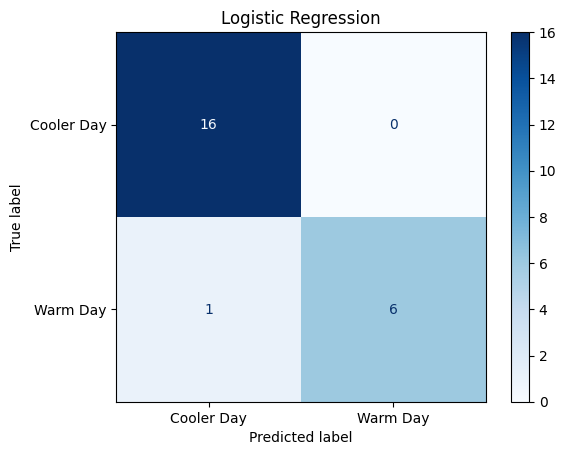

In [45]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)


X = df[['humidity', 'wind_speed', 'meanpressure']]
y = (df['meantemp'] >= 25).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

log_model = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000)
)
log_model.fit(X_train, y_train)
pred_log = log_model.predict(X_test)
print("Precision:", precision_score(y_test, pred_log, zero_division=0))
print("Recall:", recall_score(y_test, pred_log, zero_division=0))
print("F1 Score:", f1_score(y_test, pred_log, zero_division=0))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, pred_log))
print("\nClassification Report:\n", classification_report(
    y_test, pred_log,
    target_names=['Cooler Day', 'Warm Day'],
    zero_division=0
))
print("Accuracy:", accuracy_score(y_test, pred_log))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_log,
    display_labels=['Cooler Day', 'Warm Day'],
    cmap='Blues'
)
plt.title("Logistic Regression")
plt.show()
